# 02 · Regresyon Modelleri
Gerçek bir veri seti (**Diabetes** – 442 hasta, 10 özellik, hedef: 1 yıl sonraki hastalık ilerleme skoru) üzerinde regresyon modellerini karşılaştırıyoruz.

| Model | Ceza terimi | Ne zaman? |
|---|---|---|
| **Ridge (L2)** | $\alpha\sum\beta_i^2$ | Çoklu doğrusallık var, tüm değişkenler önemli |
| **Lasso (L1)** | $\alpha\sum|\beta_i|$ | Değişken seçimi istiyorsunuz (bazı β'ları 0 yapar) |
| **ElasticNet** | L1 + L2 | Çok sayıda korelasyonlu değişken |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
%matplotlib inline

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, r2_score

## 1. Veri

In [3]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
print("Boyut:", X.shape, "| Eksik değer:", X.isna().sum().sum())
X.head()

Boyut: (442, 10) | Eksik değer: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


**Yorum:** Eksik değer yok. Özellikler (yaş, cinsiyet, BMI, tansiyon, 6 kan değeri) veri setinde önceden ortalaması 0 olacak şekilde ölçeklenmiş.

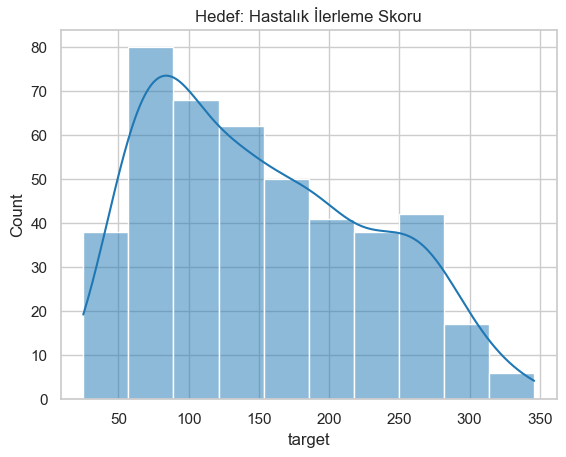

In [4]:
sns.histplot(y, kde=True, color="tab:blue"); plt.title("Hedef: Hastalık İlerleme Skoru"); plt.show()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Yorum:** Hedef hafif sağa çarpık, 25–346 aralığında. Veriyi %80 train / %20 test olarak ayırdık.

## 2. Lineer, Ridge, Lasso, ElasticNet
> Düzenlileştirmeli modellerde **mutlaka `StandardScaler`** kullanın. `...CV` sınıfları en iyi `alpha`'yı çapraz doğrulama ile kendisi seçer.

In [5]:
alphas = np.logspace(-3, 3, 50)
lineer_modeller = {
    "Linear":     LinearRegression(),
    "Ridge":      RidgeCV(alphas=alphas),
    "Lasso":      LassoCV(alphas=alphas, max_iter=10_000),
    "ElasticNet": ElasticNetCV(alphas=alphas, l1_ratio=[.1, .5, .9], max_iter=10_000),
}
sonuclar, fitted = [], {}
for ad, m in lineer_modeller.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", m)]).fit(X_train, y_train)
    fitted[ad] = pipe
    p = pipe.predict(X_test)
    sonuclar.append({"Model": ad, "Test R²": r2_score(y_test, p), "Test MAE": mean_absolute_error(y_test, p),
                     "alpha": getattr(pipe.named_steps["model"], "alpha_", None)})
pd.DataFrame(sonuclar).round(3)

,Model,Test R²,Test MAE,alpha
0,Linear,0.453,42.794,NaN
1,Ridge,0.454,42.814,1.151
2,Lasso,0.471,42.777,1.526
3,ElasticNet,0.461,42.981,0.121


**Yorum:** Bu veri küçük ve değişken sayısı az olduğu için düzenlileştirmenin katkısı sınırlı; dört model de benzer R² verir. Düzenlileştirme, değişken sayısı fazla veya veri az olduğunda çok daha belirleyici olur.

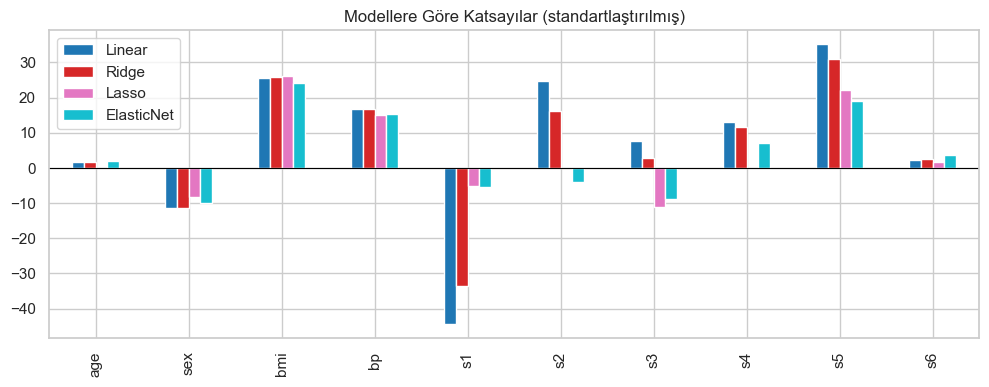

Lasso'nun sıfırladığı değişkenler: ['s2', 's4']


In [6]:
coefs = pd.DataFrame({ad: fitted[ad].named_steps["model"].coef_ for ad in fitted}, index=X.columns)
coefs.plot.bar(figsize=(12, 4), colormap="tab10"); plt.axhline(0, color="black", lw=0.8)
plt.title("Modellere Göre Katsayılar (standartlaştırılmış)"); plt.show()
print("Lasso'nun sıfırladığı değişkenler:", list(X.columns[fitted["Lasso"].named_steps["model"].coef_ == 0]))

**Yorum:** Lasso bazı katsayıları tam **0** yaparak otomatik **değişken seçimi** yapar; Ridge katsayıları küçültür ama sıfırlamaz. En etkili değişkenler genellikle `bmi`, `s5` ve `bp`'dir.

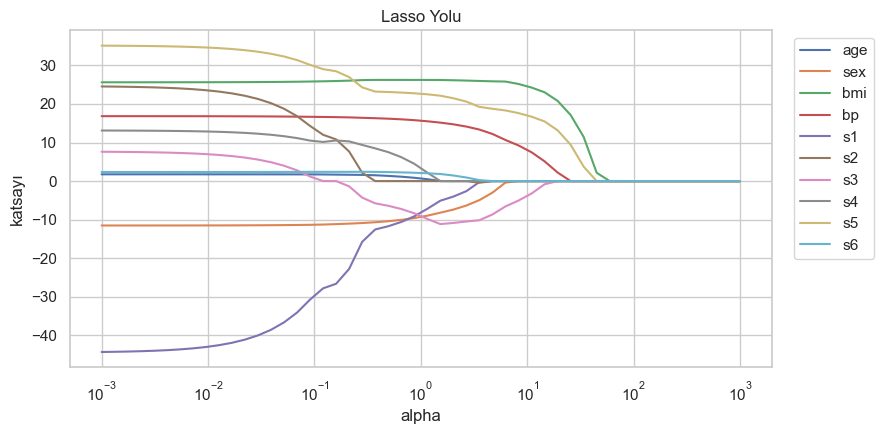

In [7]:
# Lasso yolu: alpha büyüdükçe katsayılar sıfıra gider
Xs = StandardScaler().fit_transform(X_train)
yol = [Lasso(alpha=a, max_iter=10_000).fit(Xs, y_train).coef_ for a in alphas]
plt.figure(figsize=(9, 4.5))
for i, col in enumerate(X.columns):
    plt.plot(alphas, [c[i] for c in yol], label=col)
plt.xscale("log"); plt.xlabel("alpha"); plt.ylabel("katsayı"); plt.title("Lasso Yolu")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Yorum:** Ceza (alpha) arttıkça önemsiz değişkenler ilk önce sıfırlanır; en son sıfırlananlar en önemli değişkenlerdir.

## 3. Polinom Regresyon (doğrusal olmayan ilişkiler)

In [8]:
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=alphas)),   # polinomla overfitting riski → Ridge ile birleştir
]).fit(X_train, y_train)
print("Özellik sayısı:", poly_model.named_steps["poly"].n_output_features_)
print("Polinom+Ridge Test R²:", round(r2_score(y_test, poly_model.predict(X_test)), 3))

Özellik sayısı: 65
Polinom+Ridge Test R²: 0.497


**Yorum:** 2. derece polinom 10 özelliği 65'e çıkarır (kareler + etkileşimler). Ridge olmadan bu kadar özellik küçük veride overfitting'e yol açardı.

## 4. Ağaç Tabanlı ve Diğer Regresörler

In [9]:
regresorler = {
    "Linear":         fitted["Linear"],
    "Ridge":          fitted["Ridge"],
    "Polinom+Ridge":  poly_model,
    "Karar Ağacı":    DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest":  RandomForestRegressor(n_estimators=300, random_state=42),
    "Grad. Boosting": GradientBoostingRegressor(random_state=42),
    "SVR":            Pipeline([("s", StandardScaler()), ("m", SVR(C=100))]),
    "KNN":            Pipeline([("s", StandardScaler()), ("m", KNeighborsRegressor(10))]),
}
tablo = []
for ad, m in regresorler.items():
    m.fit(X_train, y_train)
    tablo.append({"Model": ad,
                  "Train R²": r2_score(y_train, m.predict(X_train)),
                  "Test R²": r2_score(y_test, m.predict(X_test)),
                  "Test MAE": mean_absolute_error(y_test, m.predict(X_test))})
tablo = pd.DataFrame(tablo).set_index("Model").sort_values("Test R²", ascending=False)
tablo.round(3)

,Train R²,Test R²,Test MAE
Model,,,
SVR,0.668,0.508,39.419
Polinom+Ridge,0.560,0.497,41.676
Ridge,0.528,0.454,42.814
Grad. Boosting,0.836,0.453,44.603
Linear,0.528,0.453,42.794
Random Forest,0.924,0.434,44.578
KNN,0.523,0.402,45.111
Karar Ağacı,0.585,0.326,47.045


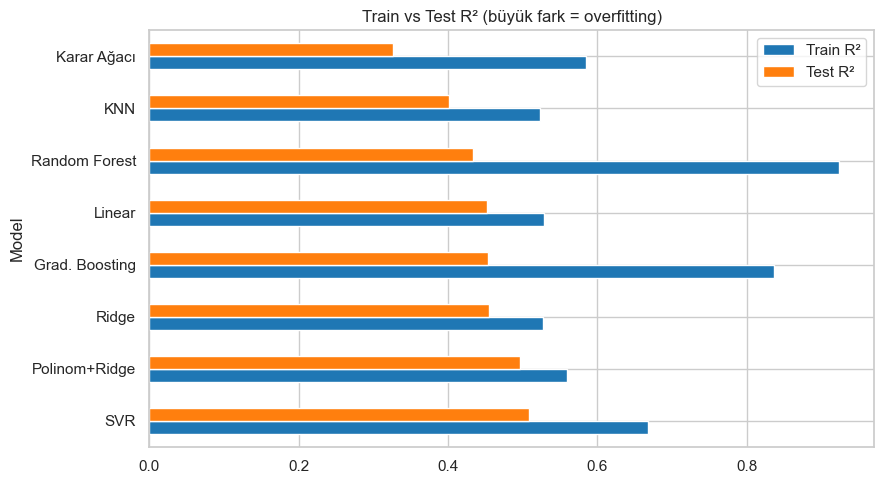

In [10]:
tablo[["Train R²", "Test R²"]].plot.barh(figsize=(9, 5), color=["tab:blue", "tab:orange"])
plt.title("Train vs Test R² (büyük fark = overfitting)"); plt.tight_layout(); plt.show()

**Yorum:** Train R² ile Test R² arasındaki fark büyük olan modeller (genellikle Random Forest, Karar Ağacı) **overfitting** yapıyor. Bu küçük ve gürültülü veri setinde basit lineer modeller karmaşık modellerle yarışır, hatta onları geçebilir — bu yüzden her zaman bir lineer baseline kurulmalıdır.

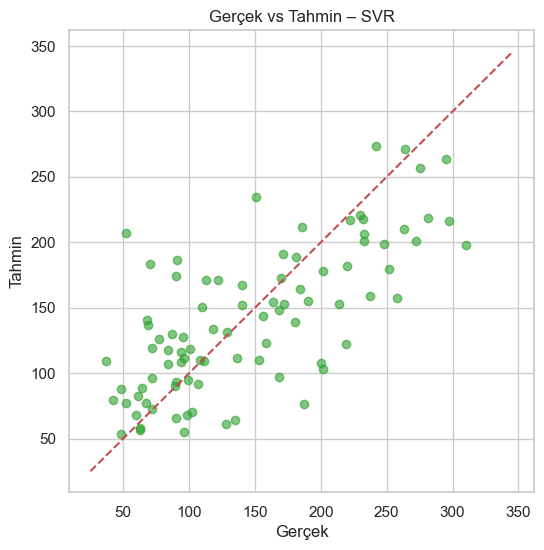

In [11]:
en_iyi = tablo.index[0]
p = regresorler[en_iyi].predict(X_test)
plt.figure(figsize=(6, 6)); plt.scatter(y_test, p, alpha=0.6, color="tab:green")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.title(f"Gerçek vs Tahmin – {en_iyi}"); plt.xlabel("Gerçek"); plt.ylabel("Tahmin"); plt.show()

## Özet
### Data Analysis Key Findings
- Diabetes veri setinde en iyi test R² ≈ 0.45–0.50 civarındadır; hedefin yarısından fazlası bu 10 değişkenle açıklanamıyor.
- Lasso bazı değişkenleri sıfırlayarak daha sade bir model sunar; en etkili değişkenler BMI, s5 ve tansiyondur.
- Ağaç tabanlı modellerde train-test farkı büyük → bu veri boyutunda overfitting eğilimi var.
### Insights or Next Steps
- Ağaç modellerinin hiperparametreleri ayarlanmalı (bkz. **10_Model_Secimi_ve_Hiperparametre**).